# Milo Differential Abundance Testing for IPF Dataset

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3

import milopy.core as milo
import milopy.plot as milopl

In [2]:
denovo_recalc = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_denovo.h5ad")
denovo_ref = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_denovo_ref_hvg.h5ad")
scarches_unlabeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_full.h5ad")
scarches_labeled = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/IPF/learned_atlas/IPF_atlas_scArches_labeled_full.h5ad")

In [3]:
query_studies = ['Banovich_Kropski_2020_disease', 'Kaminski_2020', 'Misharin_Budinger_2018_disease', 'Sheppard_2020']

In [4]:
def get_avg_da_per_cell(data):
    """
    Input: data
        whole anndata object (either denovo_recalc, denovo_ref, scarches_unlabeled, scarches_labeled)
    Output: cells_DA_avg
        vector containing the average logFC for all cells over the nhoods this cell is part of
    """
    
    
    # get vector with all cells and DA info: non-index cells have logFC of 0, index-cells have logFC != 0
    DA_per_cell = pd.merge(data.obs, data.uns["nhood_adata"].obs[["index_cell","logFC"]], how="left", left_index=True, right_on="index_cell")[["index_cell","logFC"]].fillna(0)
    DA_per_cell.index = DA_per_cell.index_cell
    DA_per_cell = DA_per_cell["logFC"]
    
    # get cells x nhoods matrix with logFC values instead of neighborhood assignment
    cells_nh_DA = (data.obsm["nhoods"].T).multiply(DA_per_cell).T
    
    # average over logFC values for each nhood
    nh_DA_avg = cells_nh_DA.sum(axis=0).A1/cells_nh_DA.getnnz(axis=0)
    
    # get cells x nhoods matrix with average logFC values per nhood instead of nhood assignment
    cells_nh_DA_avg = (data.obsm["nhoods"]).multiply(nh_DA_avg)
    
    # get vector with average logFC for all cells over all nhoods each cell is part of
    cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)
    pd.DataFrame(cells_DA_avg).fillna(0, inplace=True)
    
    #output
    return cells_DA_avg

# 1. De-Novo with recalculated HVGs

In [5]:
denovo_recalc.obs["origin"] = "reference"
denovo_recalc.obs.loc[denovo_recalc.obs.dataset.isin(query_studies),"origin"] = "query"

In [6]:
k = 50 #number of neighbors 50
n = 30 #number of pcs 30

In [7]:
sc.pp.neighbors(denovo_recalc, n_neighbors=k, n_pcs=n, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:24:58)


In [8]:
sc.tl.umap(denovo_recalc)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:38:04)


... storing 'age' as categorical
... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


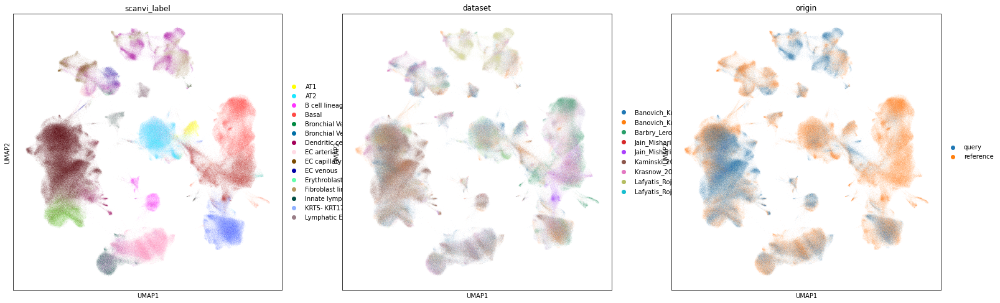

In [9]:
sc.pl.umap(denovo_recalc, color=["scanvi_label","dataset", "origin"])

In [10]:
milo.make_nhoods(denovo_recalc, prop=0.1)

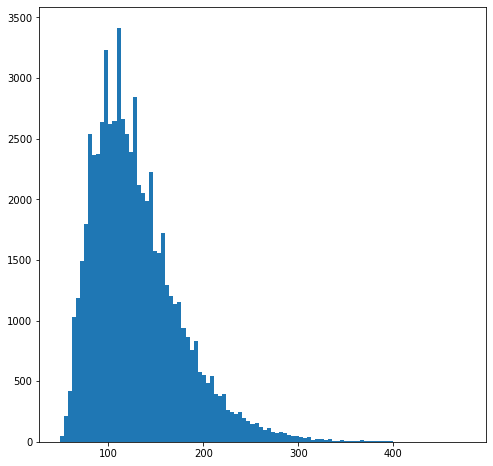

In [11]:
nhood_size = np.array(denovo_recalc.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [12]:
milo.count_nhoods(denovo_recalc, sample_col="sample")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:119: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [13]:
denovo_recalc.obs["origin_continuous"] = denovo_recalc.obs["origin"].cat.codes

In [14]:
milo.DA_nhoods(denovo_recalc, design="~origin_continuous")

/opt/python/lib/python3.8/site-packages/rpy2/robjects/vectors.py:980: UserWarning: R object inheriting from "POSIXct" but without attribute "tzone".
  warnings.warn('R object inheriting from "POSIXct" but without '


In [15]:
denovo_recalc.obs['row_num'] = np.arange(len(denovo_recalc))

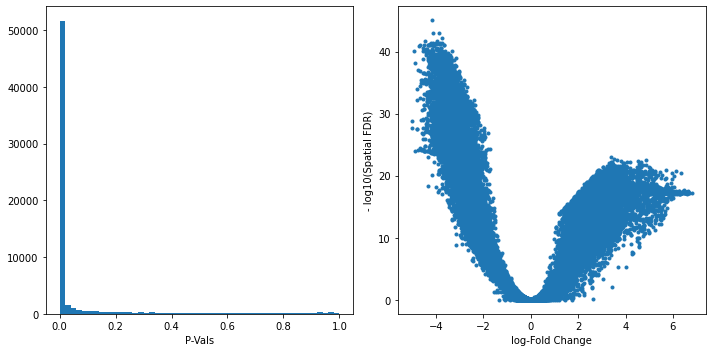

In [16]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(denovo_recalc.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(denovo_recalc.uns["nhood_adata"].obs.logFC, -np.log10(denovo_recalc.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [17]:
import milopy.utils
milopy.utils.build_nhood_graph(denovo_recalc)

/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:119: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


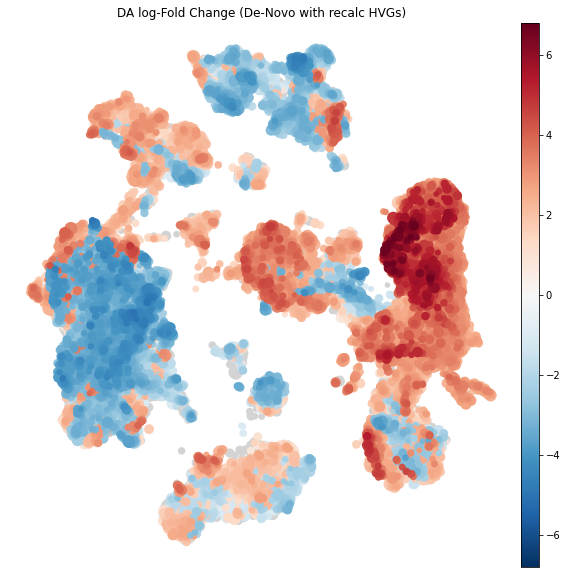

In [18]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(denovo_recalc, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (De-Novo with recalc HVGs)"
                       )

In [19]:
milopy.utils.annotate_nhoods(denovo_recalc, anno_col='C_scANVI')

Text(0.5, 0, 'celltype fraction')

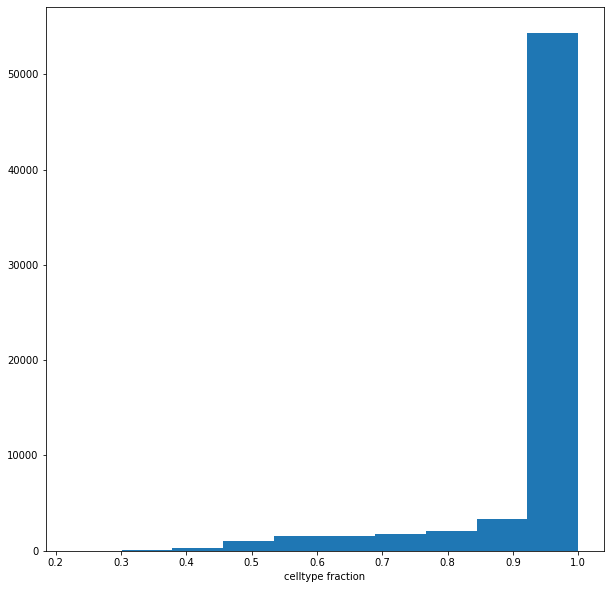

In [20]:
plt.hist(denovo_recalc.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [21]:
denovo_recalc.uns['nhood_adata'].obs.loc[denovo_recalc.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


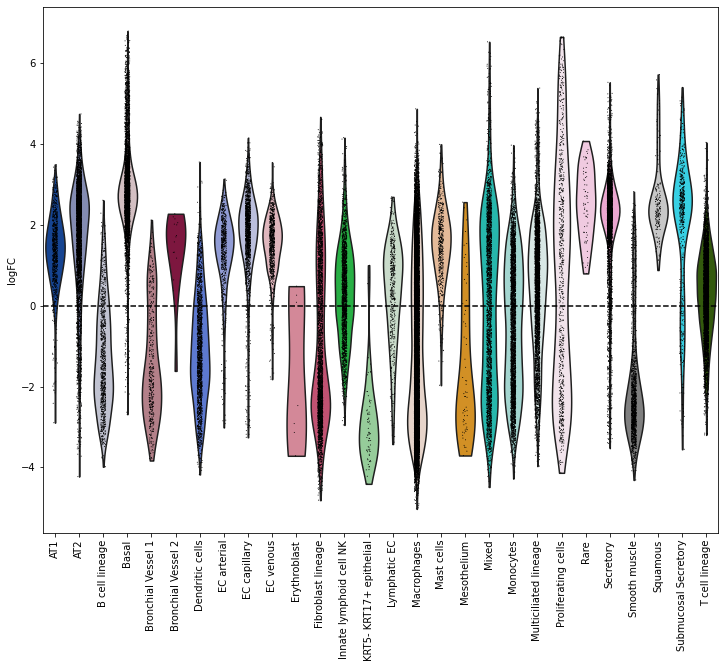

In [22]:
sc.pl.violin(denovo_recalc.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

In [23]:
denovo_recalc.obs["logFC_avg"] = get_avg_da_per_cell(denovo_recalc)

<ipython-input-4-0eaed7d71107>:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


In [24]:
denovo_recalc_save = denovo_recalc.copy()

In [25]:
del denovo_recalc_save.uns["nhood_adata"]

In [26]:
denovo_recalc_save.write("/home/jan.domke/server_home/Comparison/Data/IPF/ipf_denovo_recalc_milo.h5ad")

... storing 'highly_variable_intersection-0' as categorical


# 2. unlabeled scArches

In [27]:
scarches_unlabeled.obs["origin"] = "reference"
scarches_unlabeled.obs.loc[scarches_unlabeled.obs.dataset.isin(query_studies),"origin"] = "query"

In [28]:
sc.pp.neighbors(scarches_unlabeled, n_neighbors=50, n_pcs=30, use_rep="X_scArches")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:28:37)


In [29]:
sc.tl.umap(scarches_unlabeled)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:35:55)


... storing 'age' as categorical
... storing 'origin' as categorical


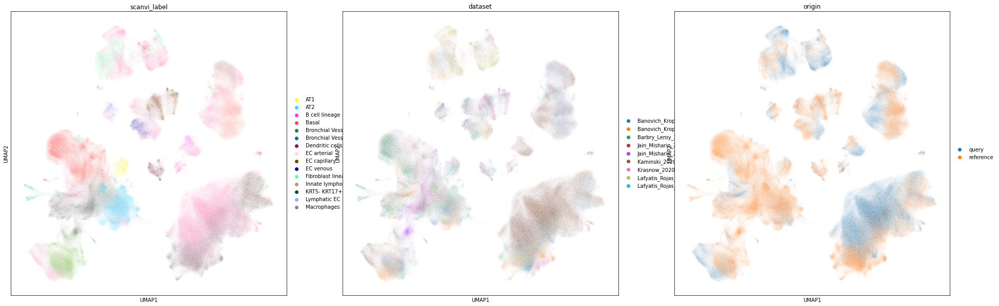

In [30]:
sc.pl.umap(scarches_unlabeled, color=["scanvi_label","dataset", "origin"])

In [31]:
milo.make_nhoods(scarches_unlabeled, prop=0.1)

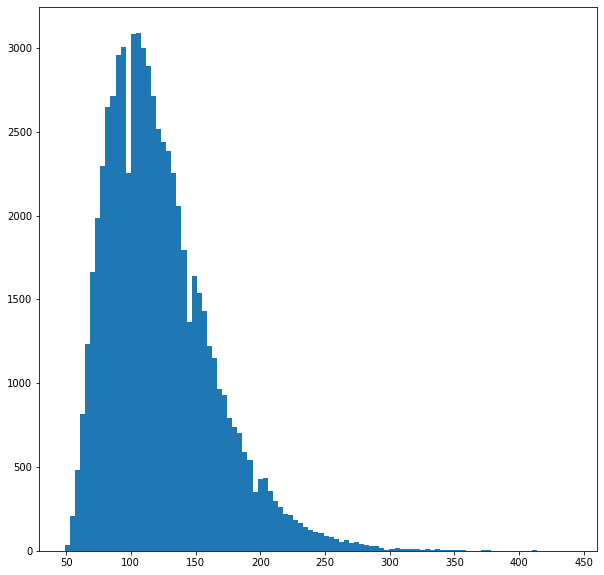

In [32]:
nhood_size = np.array(scarches_unlabeled.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [33]:
milo.count_nhoods(scarches_unlabeled, sample_col="sample")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:119: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [34]:
scarches_unlabeled.obs["origin_continuous"] = scarches_unlabeled.obs["origin"].cat.codes

In [35]:
milo.DA_nhoods(scarches_unlabeled, design="~origin_continuous")

/opt/python/lib/python3.8/site-packages/rpy2/robjects/vectors.py:980: UserWarning: R object inheriting from "POSIXct" but without attribute "tzone".
  warnings.warn('R object inheriting from "POSIXct" but without '


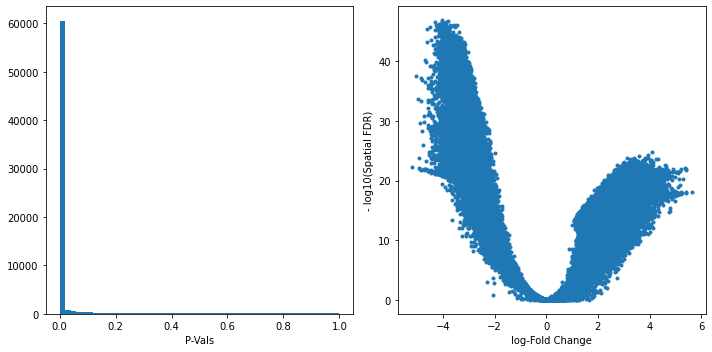

In [36]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(scarches_unlabeled.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(scarches_unlabeled.uns["nhood_adata"].obs.logFC, -np.log10(scarches_unlabeled.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [37]:
milopy.utils.build_nhood_graph(scarches_unlabeled)

/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:119: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


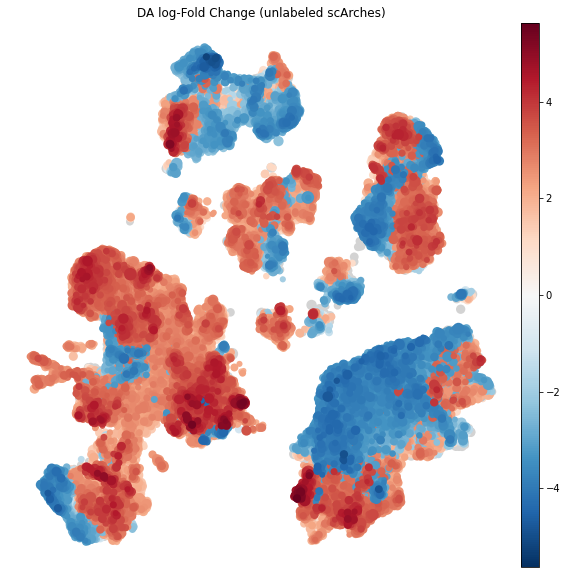

In [38]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(scarches_unlabeled, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (unlabeled scArches)"
                       )

In [39]:
milopy.utils.annotate_nhoods(scarches_unlabeled, anno_col='C_scArches')

Text(0.5, 0, 'celltype fraction')

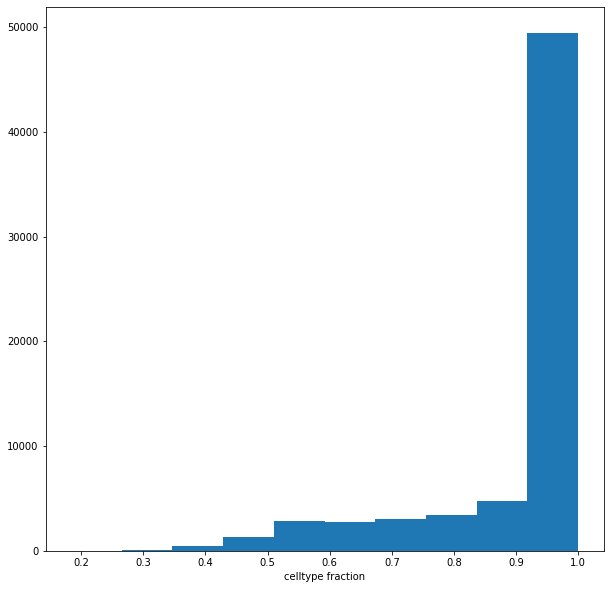

In [40]:
plt.hist(scarches_unlabeled.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [41]:
scarches_unlabeled.uns['nhood_adata'].obs.loc[scarches_unlabeled.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


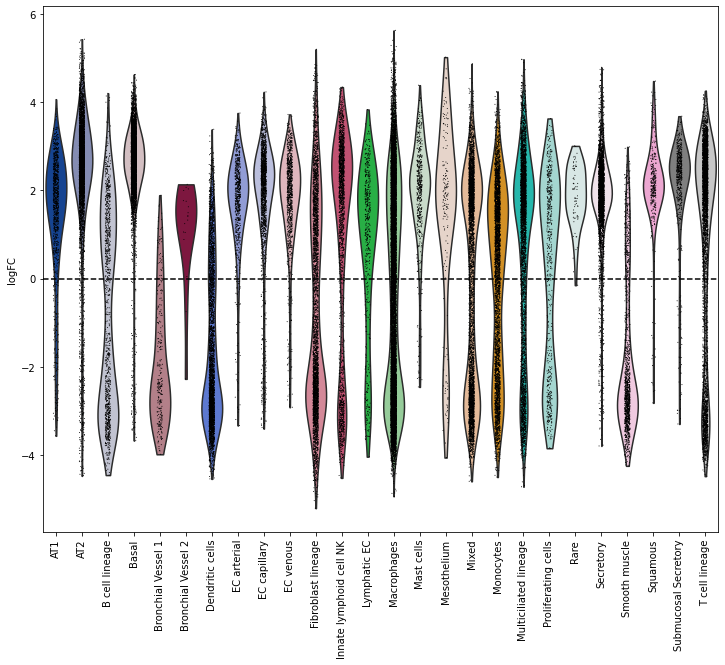

In [42]:
sc.pl.violin(scarches_unlabeled.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

In [43]:
scarches_unlabeled.obs["logFC_avg"] = get_avg_da_per_cell(scarches_unlabeled)

<ipython-input-4-0eaed7d71107>:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


In [44]:
scarches_unlabeled_save = scarches_unlabeled.copy()

In [45]:
del scarches_unlabeled_save.uns["nhood_adata"]

In [46]:
scarches_unlabeled_save.write("/home/jan.domke/server_home/Comparison/Data/IPF/ipf_scarches_unlabeled_milo.h5ad")

# 3. labeled scArches

In [47]:
scarches_labeled.obs["origin"] = "reference"
scarches_labeled.obs.loc[scarches_labeled.obs.dataset.isin(query_studies),"origin"] = "query"

In [48]:
sc.pp.neighbors(scarches_labeled, n_neighbors=50, n_pcs=30, use_rep="X_scArches")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:26:05)


In [49]:
sc.tl.umap(scarches_labeled)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:35:33)


... storing 'age' as categorical
... storing 'origin' as categorical


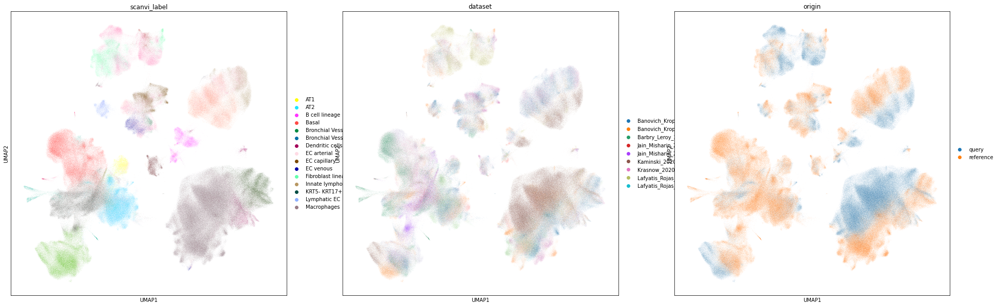

In [50]:
sc.pl.umap(scarches_labeled, color=["scanvi_label","dataset", "origin"])

In [51]:
milo.make_nhoods(scarches_labeled, prop=0.1)

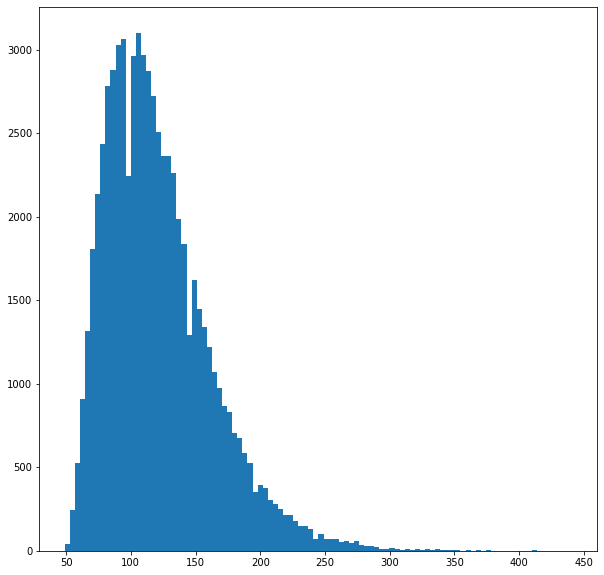

In [52]:
nhood_size = np.array(scarches_labeled.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [53]:
milo.count_nhoods(scarches_labeled, sample_col="sample")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:119: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [54]:
scarches_labeled.obs["origin_continuous"] = scarches_labeled.obs["origin"].cat.codes

In [55]:
milo.DA_nhoods(scarches_labeled, design="~origin_continuous")

/opt/python/lib/python3.8/site-packages/rpy2/robjects/vectors.py:980: UserWarning: R object inheriting from "POSIXct" but without attribute "tzone".
  warnings.warn('R object inheriting from "POSIXct" but without '


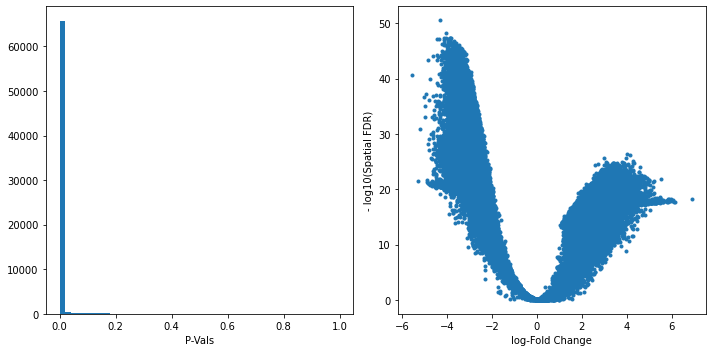

In [56]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(scarches_labeled.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(scarches_labeled.uns["nhood_adata"].obs.logFC, -np.log10(scarches_labeled.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [57]:
milopy.utils.build_nhood_graph(scarches_labeled)

/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:119: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


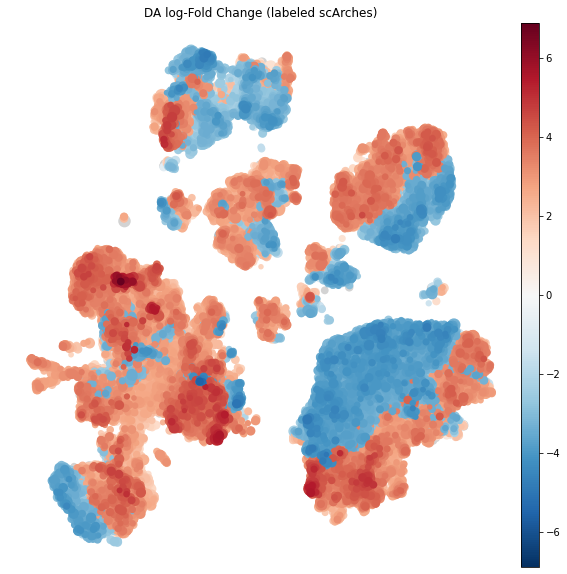

In [58]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(scarches_labeled, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (labeled scArches)"
                       )

In [59]:
milopy.utils.annotate_nhoods(scarches_labeled, anno_col='scanvi_label')

Text(0.5, 0, 'celltype fraction')

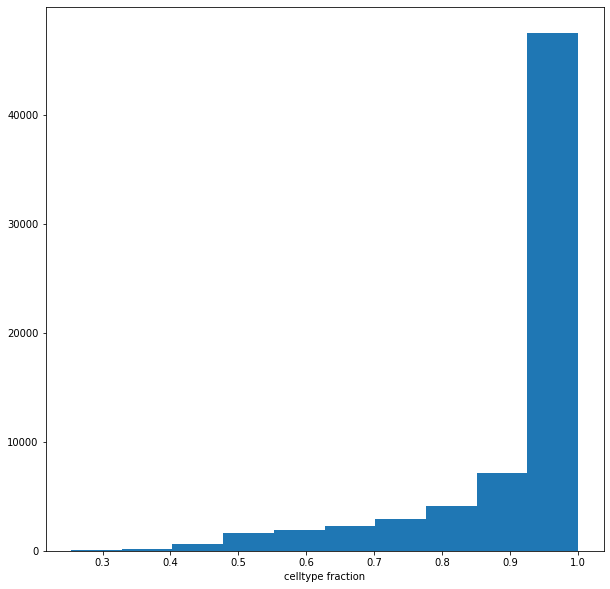

In [60]:
plt.hist(scarches_labeled.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [61]:
scarches_labeled.uns['nhood_adata'].obs.loc[scarches_labeled.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


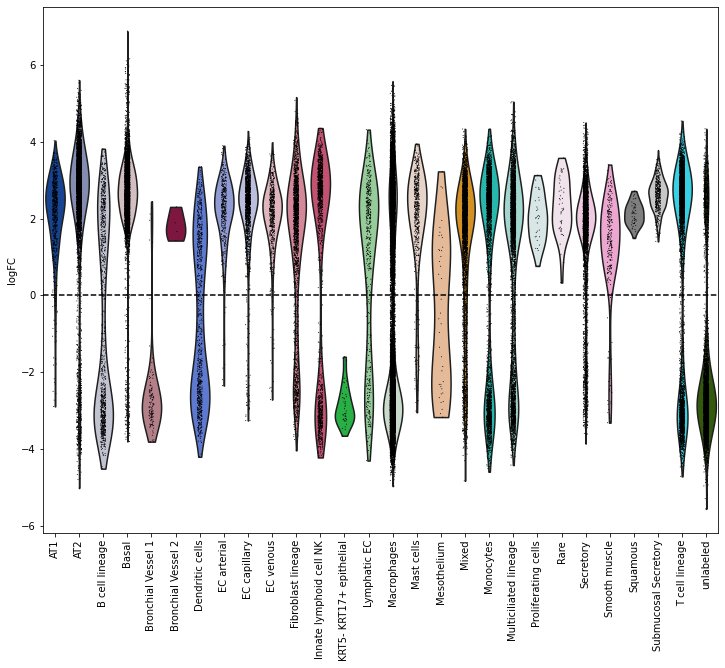

In [62]:
sc.pl.violin(scarches_labeled.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

In [63]:
scarches_labeled.obs["logFC_avg"] = get_avg_da_per_cell(scarches_labeled)

<ipython-input-4-0eaed7d71107>:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


In [64]:
scarches_labeled_save = scarches_labeled.copy()

In [65]:
del scarches_labeled_save.uns["nhood_adata"]

In [66]:
scarches_labeled_save.write("/home/jan.domke/server_home/Comparison/Data/IPF/ipf_scarches_labeled_milo.h5ad")

# 4. De-Novo with reference HVGs

In [67]:
denovo_ref.obs["origin"] = "reference"
denovo_ref.obs.loc[denovo_ref.obs.dataset.isin(query_studies),"origin"] = "query"

In [68]:
sc.pp.neighbors(denovo_ref, n_neighbors=50, n_pcs=30, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:27:52)


In [69]:
sc.tl.umap(denovo_ref)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:36:58)


... storing 'age' as categorical
... storing 'origin' as categorical
... storing 'highly_variable_intersection-0' as categorical


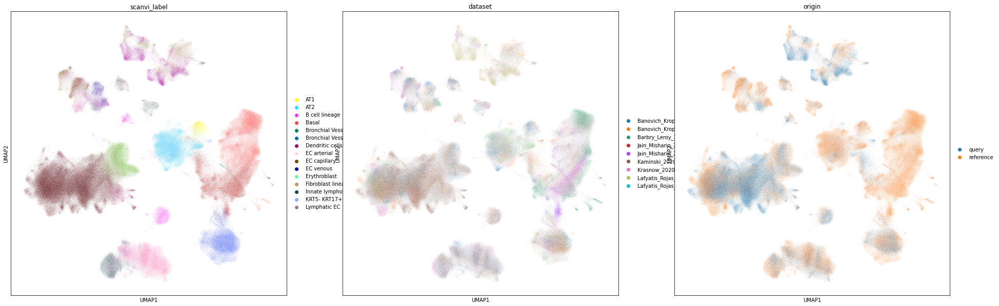

In [70]:
sc.pl.umap(denovo_ref, color=["scanvi_label","dataset", "origin"])

In [71]:
milo.make_nhoods(denovo_ref, prop=0.1)

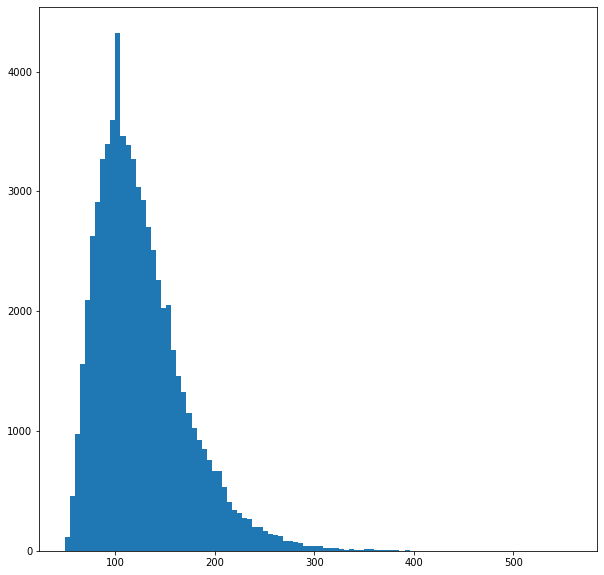

In [72]:
nhood_size = np.array(denovo_ref.obsm["nhoods"].sum(0)).ravel()
plt.hist(nhood_size, bins=100);

In [73]:
milo.count_nhoods(denovo_ref, sample_col="sample")

/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:119: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [74]:
denovo_ref.obs["origin_continuous"] = denovo_ref.obs["origin"].cat.codes

In [75]:
milo.DA_nhoods(denovo_ref, design="~origin_continuous")

/opt/python/lib/python3.8/site-packages/rpy2/robjects/vectors.py:980: UserWarning: R object inheriting from "POSIXct" but without attribute "tzone".
  warnings.warn('R object inheriting from "POSIXct" but without '


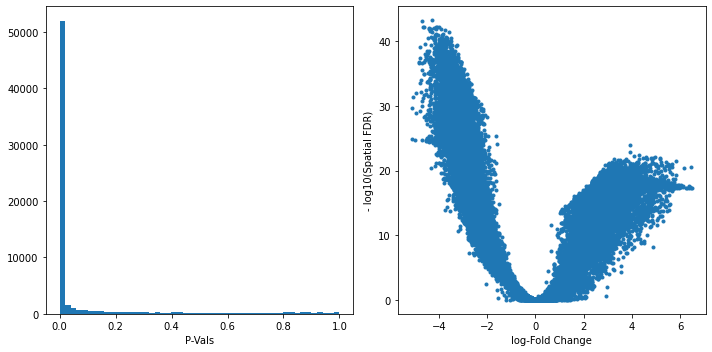

In [76]:
old_figsize = plt.rcParams["figure.figsize"]
plt.rcParams["figure.figsize"] = [10,5]
plt.subplot(1,2,1)
plt.hist(denovo_ref.uns["nhood_adata"].obs.PValue, bins=50);
plt.xlabel("P-Vals");
plt.subplot(1,2,2)
plt.plot(denovo_ref.uns["nhood_adata"].obs.logFC, -np.log10(denovo_ref.uns["nhood_adata"].obs.SpatialFDR), '.');
plt.xlabel("log-Fold Change");
plt.ylabel("- log10(Spatial FDR)");
plt.tight_layout()
plt.rcParams["figure.figsize"] = old_figsize

In [77]:
milopy.utils.build_nhood_graph(denovo_ref)

/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


/opt/python/lib/python3.8/site-packages/anndata/_core/anndata.py:119: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)


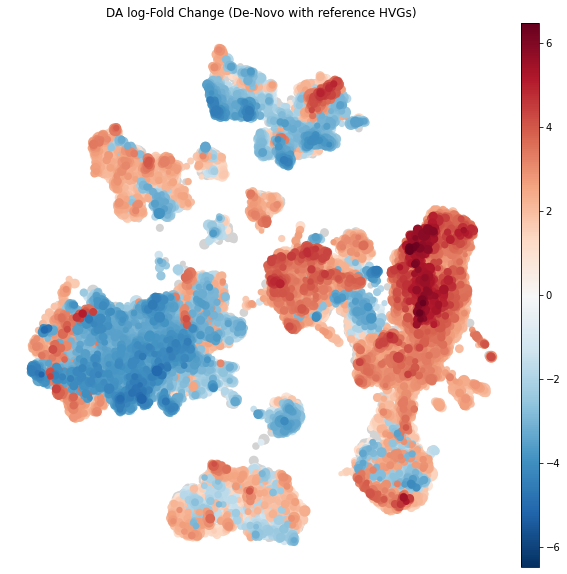

In [78]:
plt.rcParams["figure.figsize"] = [10,10]
milopl.plot_nhood_graph(denovo_ref, 
                        alpha=0.01, ## SpatialFDR level (1%) 
                        min_size=2, ## Size of smallest dot
                        title="DA log-Fold Change (De-Novo with reference HVGs)"
                       )

In [79]:
milopy.utils.annotate_nhoods(denovo_ref, anno_col='scanvi_label')

Text(0.5, 0, 'celltype fraction')

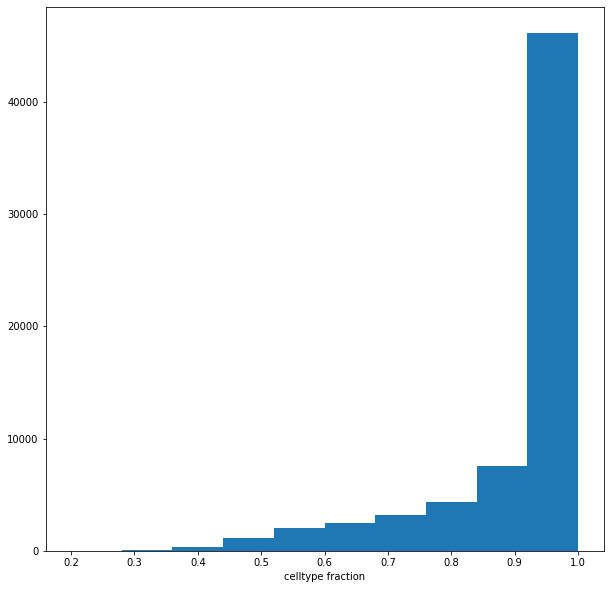

In [80]:
plt.hist(denovo_ref.uns['nhood_adata'].obs["nhood_annotation_frac"]);
plt.xlabel("celltype fraction")

In [81]:
denovo_ref.uns['nhood_adata'].obs.loc[denovo_ref.uns['nhood_adata'].obs["nhood_annotation_frac"] < 0.6, "nhood_annotation"] = "Mixed"

... storing 'nhood_annotation' as categorical


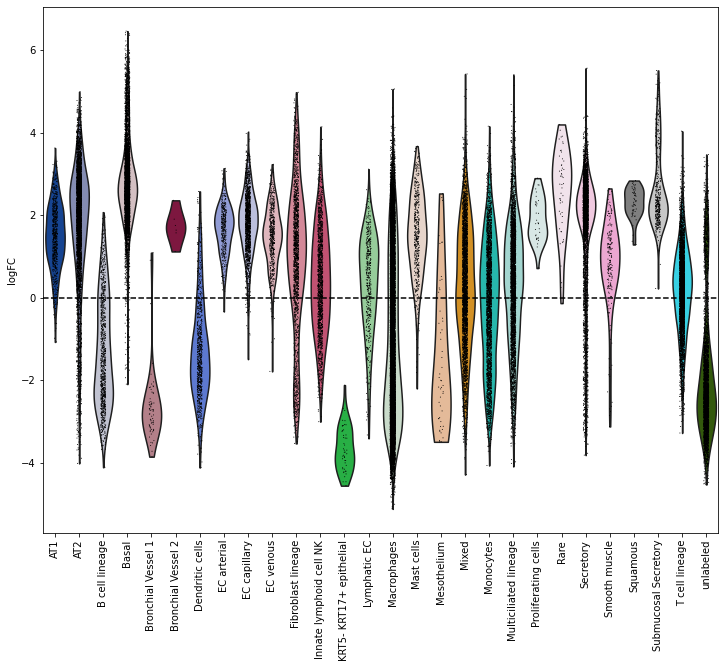

In [82]:
sc.pl.violin(denovo_ref.uns['nhood_adata'], "logFC", groupby="nhood_annotation", rotation=90, show=False);
plt.axhline(y=0, color='black', linestyle='--');
plt.show()

In [83]:
denovo_ref.obs["logFC_avg"] = get_avg_da_per_cell(denovo_ref)

<ipython-input-4-0eaed7d71107>:25: RuntimeWarning: invalid value encountered in true_divide
  cells_DA_avg = cells_nh_DA_avg.sum(axis=1).A1/cells_nh_DA.getnnz(axis=1)


In [84]:
denovo_ref_save = denovo_ref.copy()

In [85]:
del denovo_ref_save.uns["nhood_adata"]

In [86]:
denovo_ref_save.write("/home/jan.domke/server_home/Comparison/Data/IPF/ipf_denovo_ref_milo.h5ad")

# Plot differences

In [5]:
denovo_recalc = sc.read("/home/jan.domke/server_home/Comparison/Data/IPF/ipf_denovo_recalc_milo.h5ad")
denovo_ref = sc.read("/home/jan.domke/server_home/Comparison/Data/IPF/ipf_denovo_ref_milo.h5ad")
scarches_unlabeled = sc.read("/home/jan.domke/server_home/Comparison/Data/IPF/ipf_scarches_unlabeled_milo.h5ad")
scarches_labeled = sc.read("/home/jan.domke/server_home/Comparison/Data/IPF/ipf_scarches_labeled_milo.h5ad")

In [6]:
import pickle  
with open('/home/jan.domke/server_home/Comparison/Data/colordict.pkl', 'rb') as f:
        colordict = pickle.load(f)

In [7]:
colordict["Erythroblast"] = "#EA923C"

In [8]:
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("string")

In [9]:
scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label_original"] = scarches_unlabeled.obs.loc[scarches_unlabeled.obs.origin=="reference","scanvi_label"].astype(str)
scarches_unlabeled.obs["scanvi_label_original"] = scarches_unlabeled.obs["scanvi_label_original"].astype("category")

In [10]:
scarches_unlabeled.obs["diff_denovo_recalc"] = scarches_unlabeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg
scarches_unlabeled.obs["diff_scArches_labeled"] = scarches_unlabeled.obs.logFC_avg - scarches_labeled.obs.logFC_avg
scarches_labeled.obs["diff_denovo_recalc"] = scarches_labeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg
denovo_ref.obs["diff_denovo_recalc"] = denovo_ref.obs.logFC_avg - denovo_recalc.obs.logFC_avg
denovo_recalc.obs["diff_scArches_unlabeled"] = denovo_recalc.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg
denovo_recalc.obs["diff_scArches_unlabeled_comp"] = scarches_unlabeled.obs.logFC_avg - denovo_recalc.obs.logFC_avg

In [28]:
scarches_unlabeled.obs["diff_denovo_recalc_comp"] = denovo_recalc.obs.logFC_avg - scarches_unlabeled.obs.logFC_avg

In [11]:
del scarches_unlabeled.uns['scanvi_label_colors']
del scarches_labeled.uns['scanvi_label_colors']
del denovo_recalc.uns['scanvi_label_colors']
del denovo_ref.uns['scanvi_label_colors']

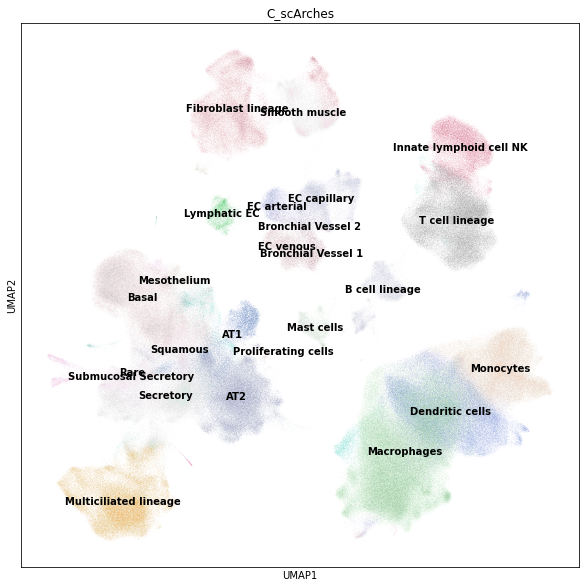

In [95]:
sc.pl.umap(scarches_unlabeled, color = "C_scArches", legend_loc = "on data")

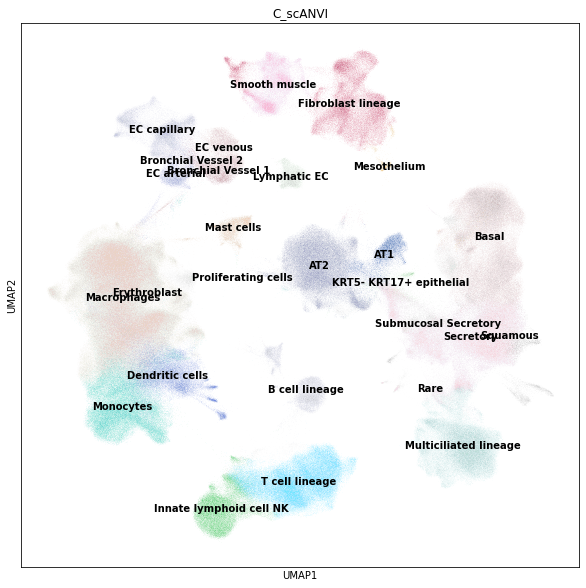

In [96]:
sc.pl.umap(denovo_recalc, color = "C_scANVI", legend_loc = "on data")

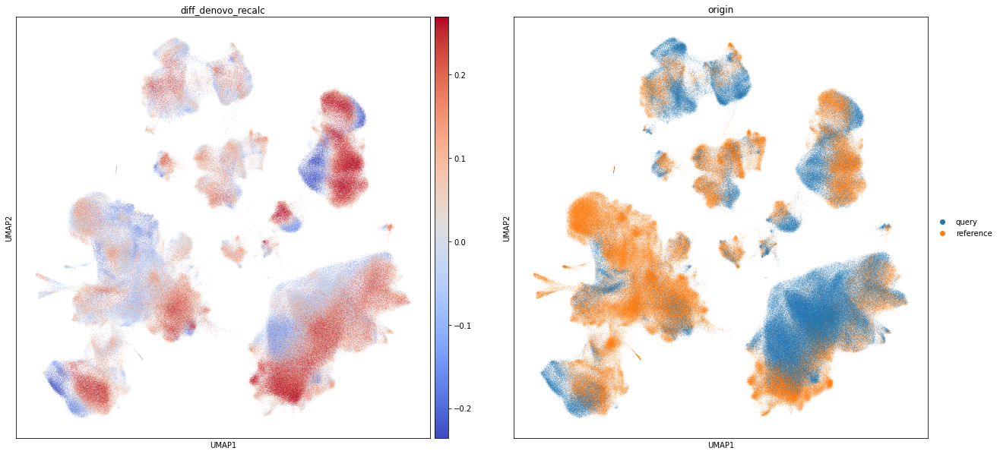

In [97]:
sc.pl.umap(scarches_unlabeled, color=["diff_denovo_recalc", "origin"], 
          vmin="p5", vmax="p95", color_map="coolwarm", size = 0.5)

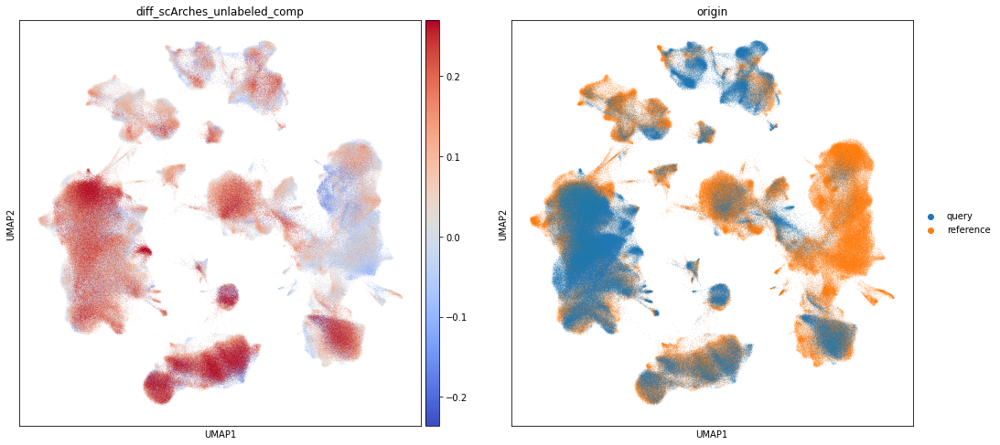

In [27]:
sc.pl.umap(denovo_recalc, color=["diff_scArches_unlabeled_comp", "origin"], 
          vmin="p5", vmax="p95", color_map="coolwarm", size = 0.5)

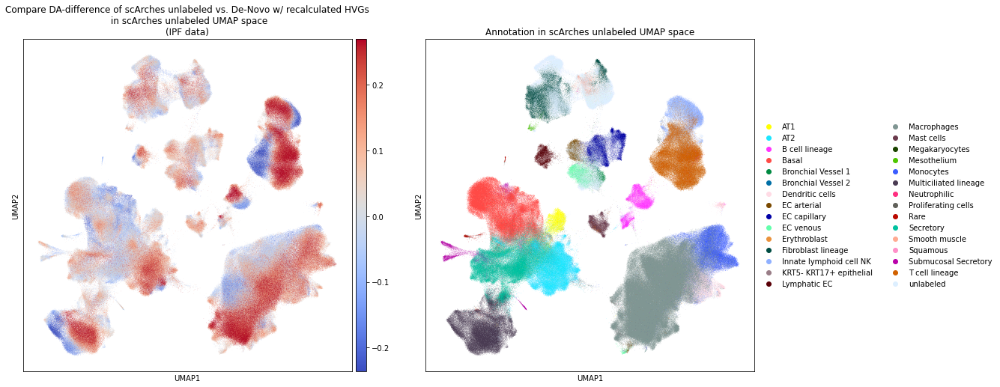

In [23]:
sc.pl.umap(scarches_unlabeled, color=["diff_denovo_recalc", "scanvi_label_original"], 
          vmin="p5", vmax="p95", color_map="coolwarm", palette = colordict, size = 0.5,
          title = ["Compare DA-difference of scArches unlabeled vs. De-Novo w/ recalculated HVGs\n in scArches unlabeled UMAP space\n(IPF data)", 
                   "Annotation in scArches unlabeled UMAP space" ])

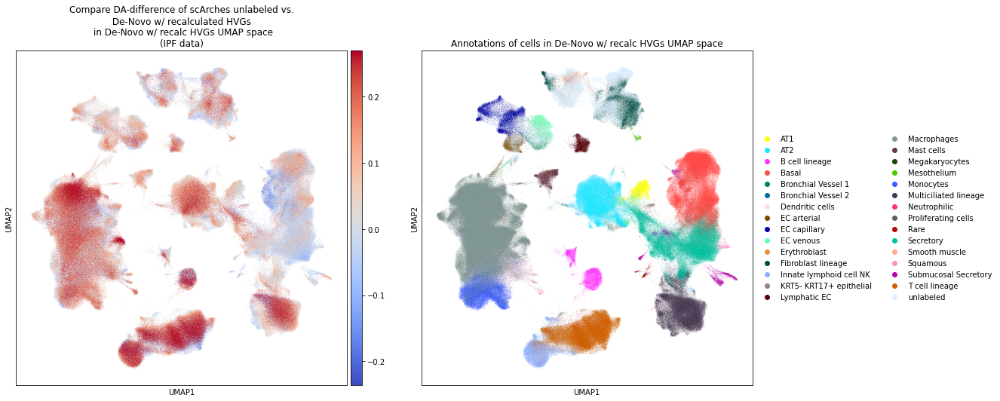

In [24]:
sc.pl.umap(denovo_recalc, color=["diff_scArches_unlabeled_comp", "scanvi_label"], 
           vmin="p5", vmax="p95", color_map = "coolwarm", palette = colordict, size = 0.5,
           title = ["Compare DA-difference of scArches unlabeled vs.\n De-Novo w/ recalculated HVGs \n in De-Novo w/ recalc HVGs UMAP space\n(IPF data)", 
                    "Annotations of cells in De-Novo w/ recalc HVGs UMAP space"])

# Violin Plots 

In [12]:
scarches_unlabeled.obs["diff_denovo_recalc_abs"] = abs(scarches_unlabeled.obs.diff_denovo_recalc)

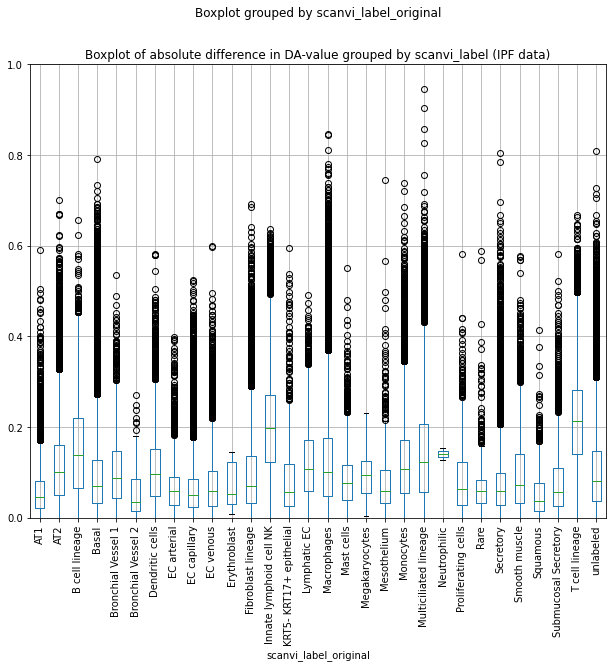

In [106]:
scarches_unlabeled.obs.boxplot(column='diff_denovo_recalc_abs',by='scanvi_label_original')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by scanvi_label (IPF data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig("/home/jan.domke/server_home/Comparison/Data/IPF/Plots/ipf_boxplot_scanvi_label.jpg")

In [13]:
cell_labels_lvl3 = ["Erythroblast", "KRT5- KRT17+ epithelial"]
cell_labels_lvl4 = ["Fibroblasts PLIN2+", "Ionocyte", "Neuroendocrine", "Langerin+ DC", "Regulatory T cells", "T cells proliferating"]

cells_lvl3 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_3"].isin(cell_labels_lvl3)]
cells_lvl3.obs["diff_denovo_recalc_abs"] = abs(cells_lvl3.obs.diff_denovo_recalc)

cells_lvl4 = scarches_unlabeled[scarches_unlabeled.obs["ann_level_4"].isin(cell_labels_lvl4)]
cells_lvl4.obs["diff_denovo_recalc_abs"] = abs(cells_lvl4.obs.diff_denovo_recalc)

/opt/python/lib/python3.8/site-packages/pandas/core/arrays/categorical.py:2487: FutureWarning: The `inplace` parameter in pandas.Categorical.remove_unused_categories is deprecated and will be removed in a future version.
  res = method(*args, **kwargs)
Trying to set attribute `.obs` of view, copying.
Trying to set attribute `.obs` of view, copying.


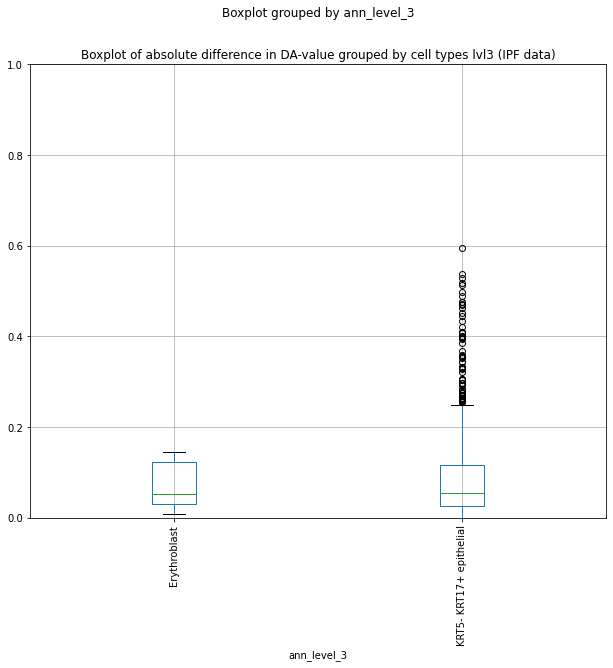

In [114]:
cells_lvl3.obs.boxplot(column='diff_denovo_recalc_abs',by='ann_level_3')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-value grouped by cell types lvl3 (IPF data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig("/home/jan.domke/server_home/Comparison/Data/IPF/Plots/ipf_boxplot_new_lvl3.jpg")

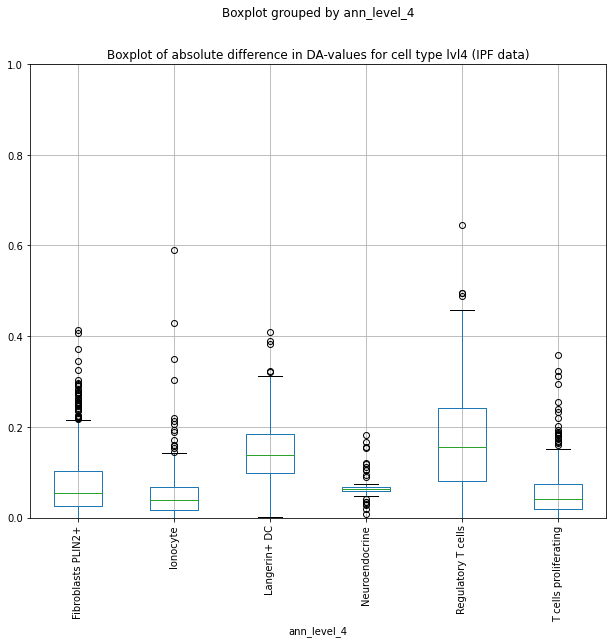

In [110]:
cells_lvl4.obs.boxplot(column='diff_denovo_recalc_abs',by='ann_level_4')
plt.xticks(rotation=90)
plt.title("Boxplot of absolute difference in DA-values for cell type lvl4 (IPF data)")
plt.ylim(0,1)
plt.subplots_adjust(bottom=0.27)
plt.savefig("/home/jan.domke/server_home/Comparison/Data/IPF/Plots/ipf_boxplot_lvl4.jpg")

# Clustering analysis

In [14]:
sc.tl.leiden(denovo_recalc, resolution= 0.1)

running Leiden clustering
    finished: found 12 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:19:20)


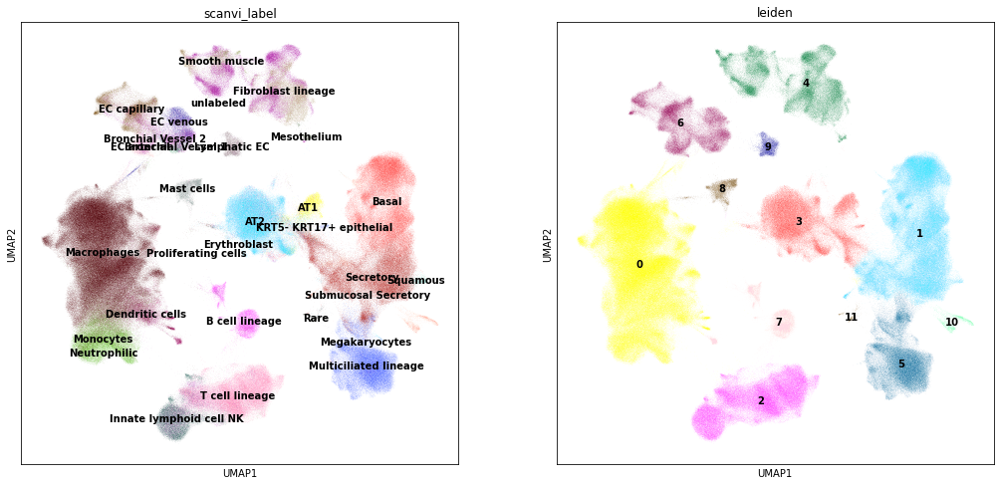

In [15]:
sc.pl.umap(denovo_recalc, color=["scanvi_label","leiden"], legend_loc="on data")

In [16]:
subset_immune = denovo_recalc[(denovo_recalc.obs.leiden == "0") | (denovo_recalc.obs.leiden == "2")].copy()

In [17]:
sc.pp.neighbors(subset_immune, n_neighbors=50, n_pcs=30, use_rep="X_scANVI")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:12:13)


In [18]:
sc.tl.umap(subset_immune)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:17:50)


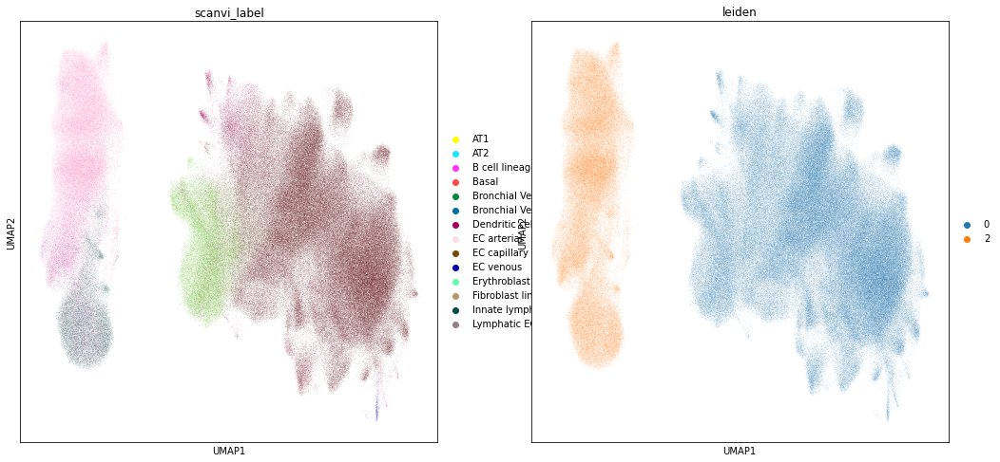

In [19]:
sc.pl.umap(subset_immune, color=["scanvi_label","leiden"])

In [20]:
sc.tl.leiden(subset_immune, resolution= 0.5,key_added = "leiden_sub")

running Leiden clustering
    finished: found 14 clusters and added
    'leiden_sub', the cluster labels (adata.obs, categorical) (0:19:21)


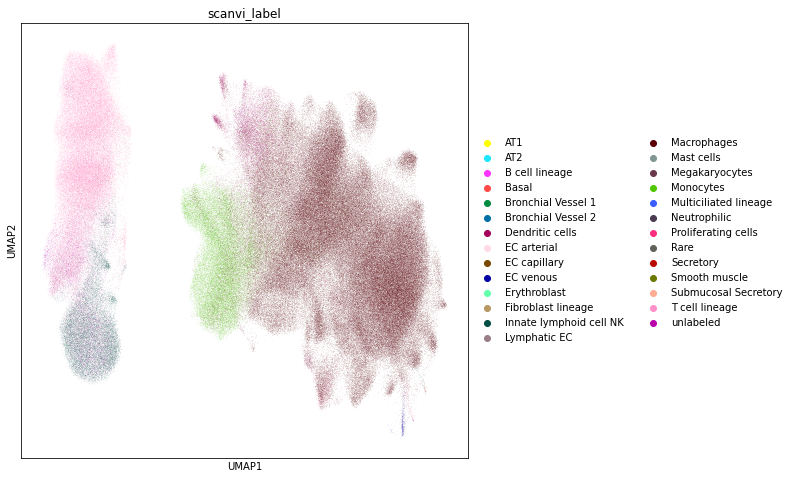

In [21]:
sc.pl.umap(subset_immune, color=["scanvi_label"])

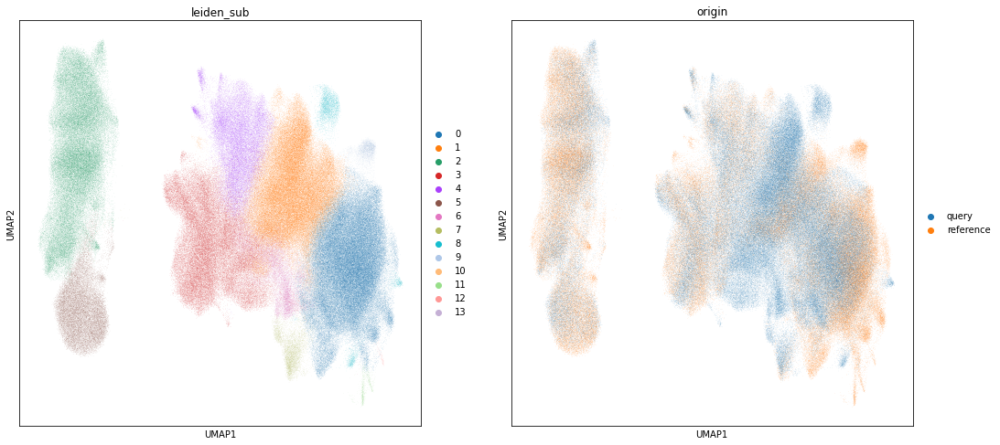

In [22]:
sc.pl.umap(subset_immune, color=["leiden_sub", "origin"])

In [124]:
subset_immune.raw.var.index = subset_immune.raw.var["gene_symbols-0"]

In [125]:
subset_immune.raw.var_names

CategoricalIndex(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR', 'CFH',
                  'FUCA2', 'GCLC', 'NFYA',
                  ...
                  nan, nan, nan, nan, nan, nan, nan, nan, nan, nan],
                 categories=['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1', 'A2ML1', 'A2ML1-AS1', 'A2ML1-AS2', ...], ordered=False, name='gene_symbols-0', dtype='category', length=48717)

In [126]:
subset_immune.raw.var.index

CategoricalIndex(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR', 'CFH',
                  'FUCA2', 'GCLC', 'NFYA',
                  ...
                  nan, nan, nan, nan, nan, nan, nan, nan, nan, nan],
                 categories=['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1', 'A2ML1', 'A2ML1-AS1', 'A2ML1-AS2', ...], ordered=False, name='gene_symbols-0', dtype='category', length=48717)

ranking genes
    finished: added to `.uns['t-test']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:01:38)


IndexError: index 25 is out of bounds for axis 0 with size 25

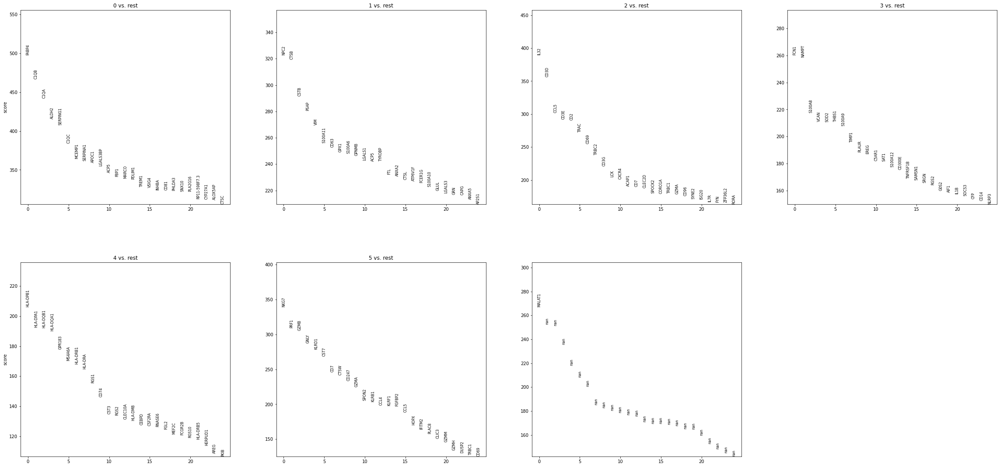

In [127]:
sc.tl.rank_genes_groups(subset_immune, 'leiden_sub', method='t-test', key_added = "t-test", use_raw=True)
sc.pl.rank_genes_groups(subset_immune, n_genes=25, sharey=False, key = "t-test", gene_symbols = "gene_symbols-0")

In [1]:
subset_immune

NameError: name 'subset_immune' is not defined

In [ ]:
sc.tl.filter_rank_genes_groups(subset_immune, min_fold_change=3, key="t-test", use_raw=True)

Filtering genes using: min_in_group_fraction: 0.25 min_fold_change: 3, max_out_group_fraction: 0.5


In [ ]:
subset_immune.uns["rank_genes_groups_filtered"]

In [ ]:
# visualize results
sc.pl.rank_genes_groups(subset_immune, key='rank_genes_groups_filtered')

In [ ]:
sc.get.rank_genes_groups_df(subset_immune, key='rank_genes_groups_filtered')

In [ ]:
# visualize results using dotplot
sc.pl.rank_genes_groups_dotplot(subset_immune, n_genes=5, key='rank_genes_groups_filtered',  gene_symbols = "gene_symbols-0")

In [59]:
sc.logging.print_versions()


-----
anndata     0.7.5
scanpy      1.8.2
sinfo       0.3.1
-----
PIL                 8.1.0
anndata             0.7.5
anyio               NA
attr                20.3.0
babel               2.9.0
backcall            0.2.0
brotli              1.0.9
certifi             2020.12.05
cffi                1.14.4
chardet             4.0.0
cloudpickle         1.6.0
constants           NA
cycler              0.10.0
cython_runtime      NA
dask                2020.12.0
dateutil            2.8.1
decorator           4.4.2
future_fstrings     NA
google              NA
h5py                2.10.0
highs_wrapper       NA
idna                2.10
igraph              0.8.3
ipykernel           5.4.3
ipython_genutils    0.2.0
ipywidgets          7.6.3
jedi                0.18.0
jinja2              2.11.2
joblib              1.0.0
json5               NA
jsonschema          3.2.0
jupyter_server      1.2.1
jupyterlab_server   2.1.2
kiwisolver          1.3.1
leidenalg           0.8.3
llvmlite            0.35.0
louv